### NaScH Analysis (Task 1 and Task 2)
1. The parameters that control free flow and congestion is sigma and density
2. First too see if different ring roads length affects flow
3. Theorectically, it should be the same through
4. First experiment set so that sigma is fixed while varying the road length
5. Second experiment is to set the road length and to vary the sigma (probability of breaking)

### Parameters that were being changed
1. The jam_speed_mps to be uniform with our group members
2. Then to give a more uniform density sweep

### toml files
1. NaSch_600, 1200, 4800
2. NaSch_1200_sigma_sweep
3. NaSch_removal

In [44]:
# Some libraries used
import tomllib
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

#### Experiment 1: To see if different ring road length affects flow while keeping everything the same

In [45]:
ROOT = Path.cwd().resolve().parent

files = {
    600: "NaSch_600.csv",
    1200: "NaSch_1200.csv",
    4800: "NaSch_4800.csv"
}

frames = []

for length, filename in files.items():
    path = ROOT / "results" / "ring" / filename

    df = pd.read_csv(path)
    df["ring_length_m"] = length
    frames.append(df)

df_all = pd.concat(frames, ignore_index=True)

In [46]:
# Some inspection
for col in df_all.columns: print(col)
df_all.head(5)

validation = (
    df_all.groupby("ring_length_m")
    .agg(
        runs=("run_id", "count"),
        densities=("density_veh_km", "nunique"),
        seeds=("seed", "nunique"),
        valid_runs=("valid", "sum")
    )
)

run_id
scenario
model
variant
seed
density_veh_km
mean_speed_mps
flow_veh_h
congested_fraction
congested_fraction_var
valid
ring_vehicles
ring_length_m


In [47]:
# Assuming that they are valid
df_valid = df_all[df_all["valid"] == True].copy()

# Measurements of interest
metrics = [
    "mean_speed_mps",
    "flow_veh_h",
    "congested_fraction",
    "congested_fraction_var"
]

# Average across seeds for each density and ring length
summary = (df_valid.groupby(["ring_length_m", "density_veh_km"])
    .agg(
        **{
            f"{metric}_mean": (metric, "mean")
            for metric in metrics
        },
        **{
            f"{metric}_std": (metric, "std")
            for metric in metrics
        },
        n_seeds=("seed", "nunique")
    )
    .reset_index()
)

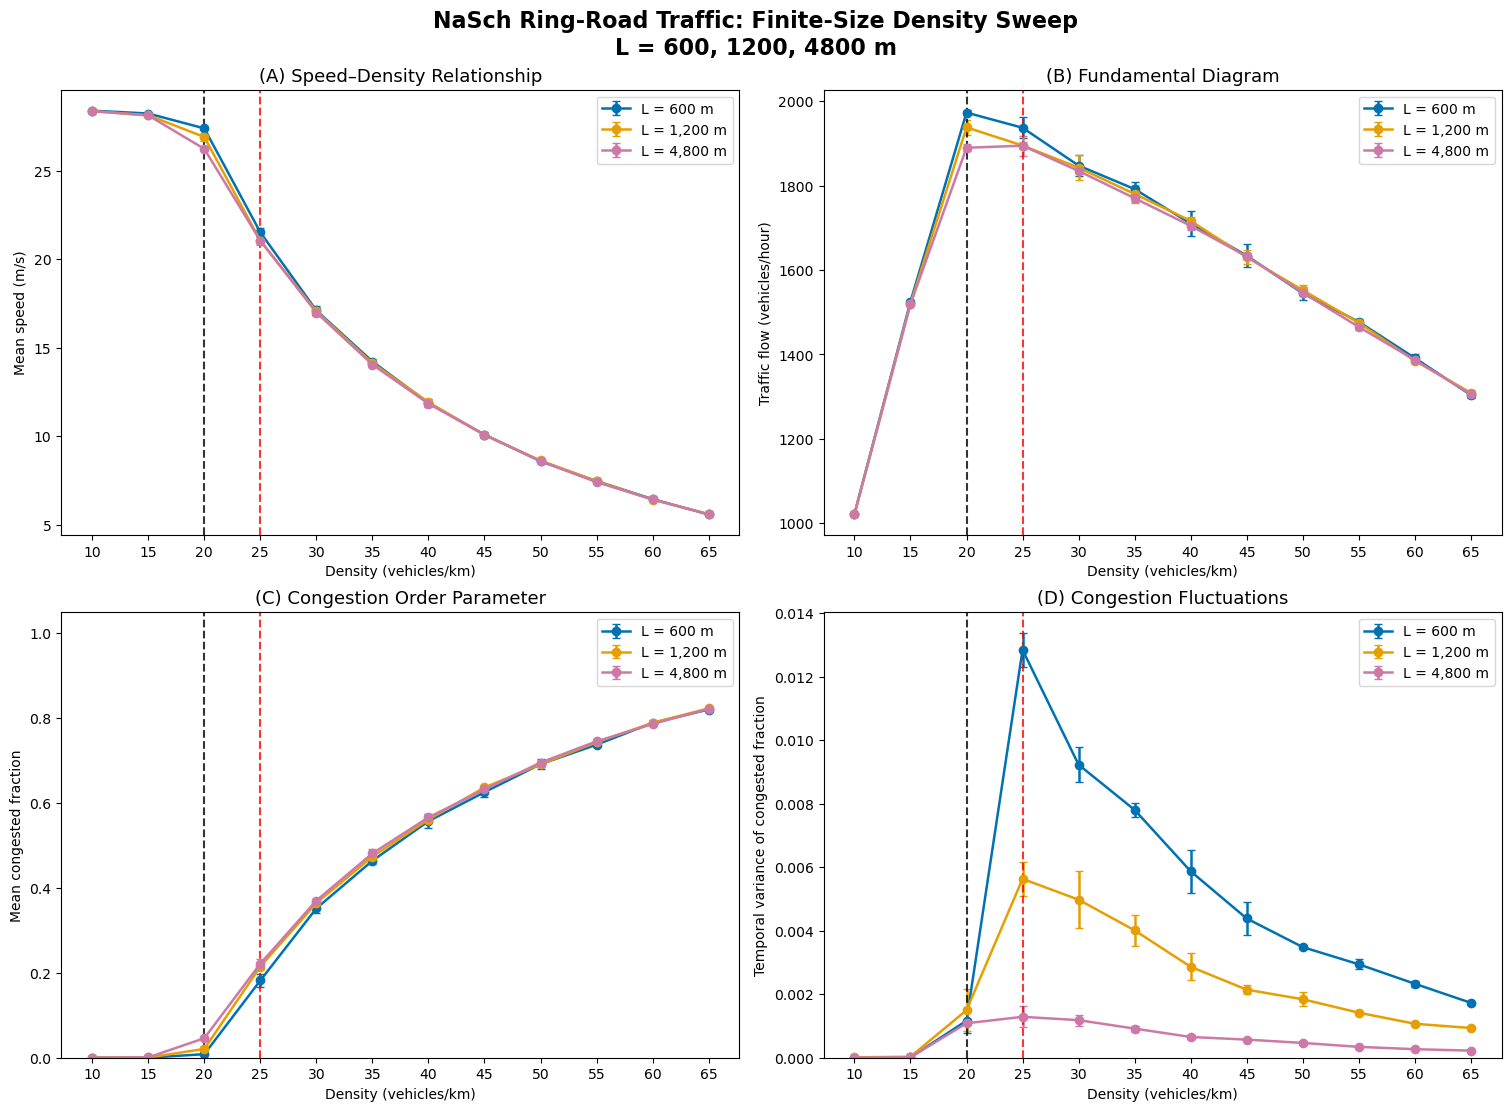

In [48]:
# To plot some figures for analysis
fig, axes = plt.subplots(2, 2, figsize=(15, 11), constrained_layout=True)

plot_config = [
    {"metric": "mean_speed_mps", "title": "(A) Speed–Density Relationship", "ylabel": "Mean speed (m/s)"},
    {"metric": "flow_veh_h", "title": "(B) Fundamental Diagram", "ylabel": "Traffic flow (vehicles/hour)"},
    {"metric": "congested_fraction", "title": "(C) Congestion Order Parameter", "ylabel": "Mean congested fraction"},
    {"metric": "congested_fraction_var", "title": "(D) Congestion Fluctuations", "ylabel": "Temporal variance of congested fraction"}
]

ring_lengths = [600, 1200, 4800]

colors = {
    600:  "#0072B2",  # Blue
    1200: "#E69F00",  # Orange
    4800: "#CC79A7"   # Reddish purple
}

for ax, config in zip(axes.flat, plot_config):

    metric = config["metric"]

    for length in ring_lengths:

        subset = summary[summary["ring_length_m"] == length].sort_values("density_veh_km")

        ax.errorbar(subset["density_veh_km"], subset[f"{metric}_mean"], yerr=subset[f"{metric}_std"].fillna(0), marker="o", linewidth=1.8, markersize=6, capsize=3, color=colors[length], label=f"L = {length:,} m")

    # Vertical black dashed line at density = 20
    ax.axvline(x=20, color="black", linestyle="--", linewidth=1.5, alpha=0.8)
    ax.axvline(x=25, color="red", linestyle="--", linewidth=1.5, alpha=0.8)

    ax.set_title(config["title"], fontsize=13)
    ax.set_xlabel("Density (vehicles/km)")
    ax.set_ylabel(config["ylabel"])

    ax.set_xticks([10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65])
    # ax.grid(alpha=0.25)
    ax.legend()

axes[1, 0].set_ylim(bottom=0)
axes[1, 0].set_ylim(top=1.05)
axes[1, 1].set_ylim(bottom=0)

fig.suptitle(
    "NaSch Ring-Road Traffic: Finite-Size Density Sweep\n"
    "L = 600, 1200, 4800 m",
    fontsize=16,
    fontweight="bold"
)

plt.show()

In [65]:
# Then to plot the space-time diagram for all the densities
from traffic_project.measurements import iter_fcd

lengths = [600, 1200, 4800]
densities = [20, 25, 30, 40]

seed = 501

time_start = 600
time_end = 1800

spatial_bin = 20
temporal_bin = 10

In [66]:
def load_fcd_for_heatmap(length, n_vehicles, seed):

    run_id = f"ring_nasch_L{length}_n{n_vehicles}_s{seed}"

    fcd_path = ROOT / "runs" / run_id / "fcd.xml"

    if not fcd_path.exists():
        raise FileNotFoundError(
            f"Missing FCD file:\n{fcd_path}\n"
            "Check the seed and run directory."
        )

    records = []

    edge_length = length / 4

    for t, vehicles in iter_fcd(fcd_path):

        if not (time_start <= t < time_end):
            continue

        for vehicle in vehicles:

            edge_id = vehicle["lane"].rsplit("_", 1)[0]

            if edge_id not in {"e0", "e1", "e2", "e3"}:
                raise ValueError(f"Unexpected edge ID: {edge_id}")

            edge_index = int(edge_id[1:])

            x = (edge_index * edge_length + vehicle["pos"]) % length

            records.append({
                "time": t,
                "position": x,
                "speed": vehicle["speed"]
            })

    if not records:
        raise ValueError(f"No trajectory observations in {fcd_path}")

    return pd.DataFrame(records)

In [67]:
def make_speed_matrix(df, length, spatial_bin=50, temporal_bin=10):

    n_space = int(np.ceil(length / spatial_bin))
    n_time = int(np.ceil((time_end - time_start) / temporal_bin))

    df = df.copy()

    df["space_idx"] = np.floor(
        df["position"] / spatial_bin
    ).astype(int).clip(0, n_space - 1)

    df["time_idx"] = np.floor(
        (df["time"] - time_start) / temporal_bin
    ).astype(int).clip(0, n_time - 1)

    matrix = (
        df.groupby(["time_idx", "space_idx"])["speed"]
        .mean()
        .unstack()
        .reindex(
            index=range(n_time),
            columns=range(n_space)
        )
    )

    return matrix.to_numpy()

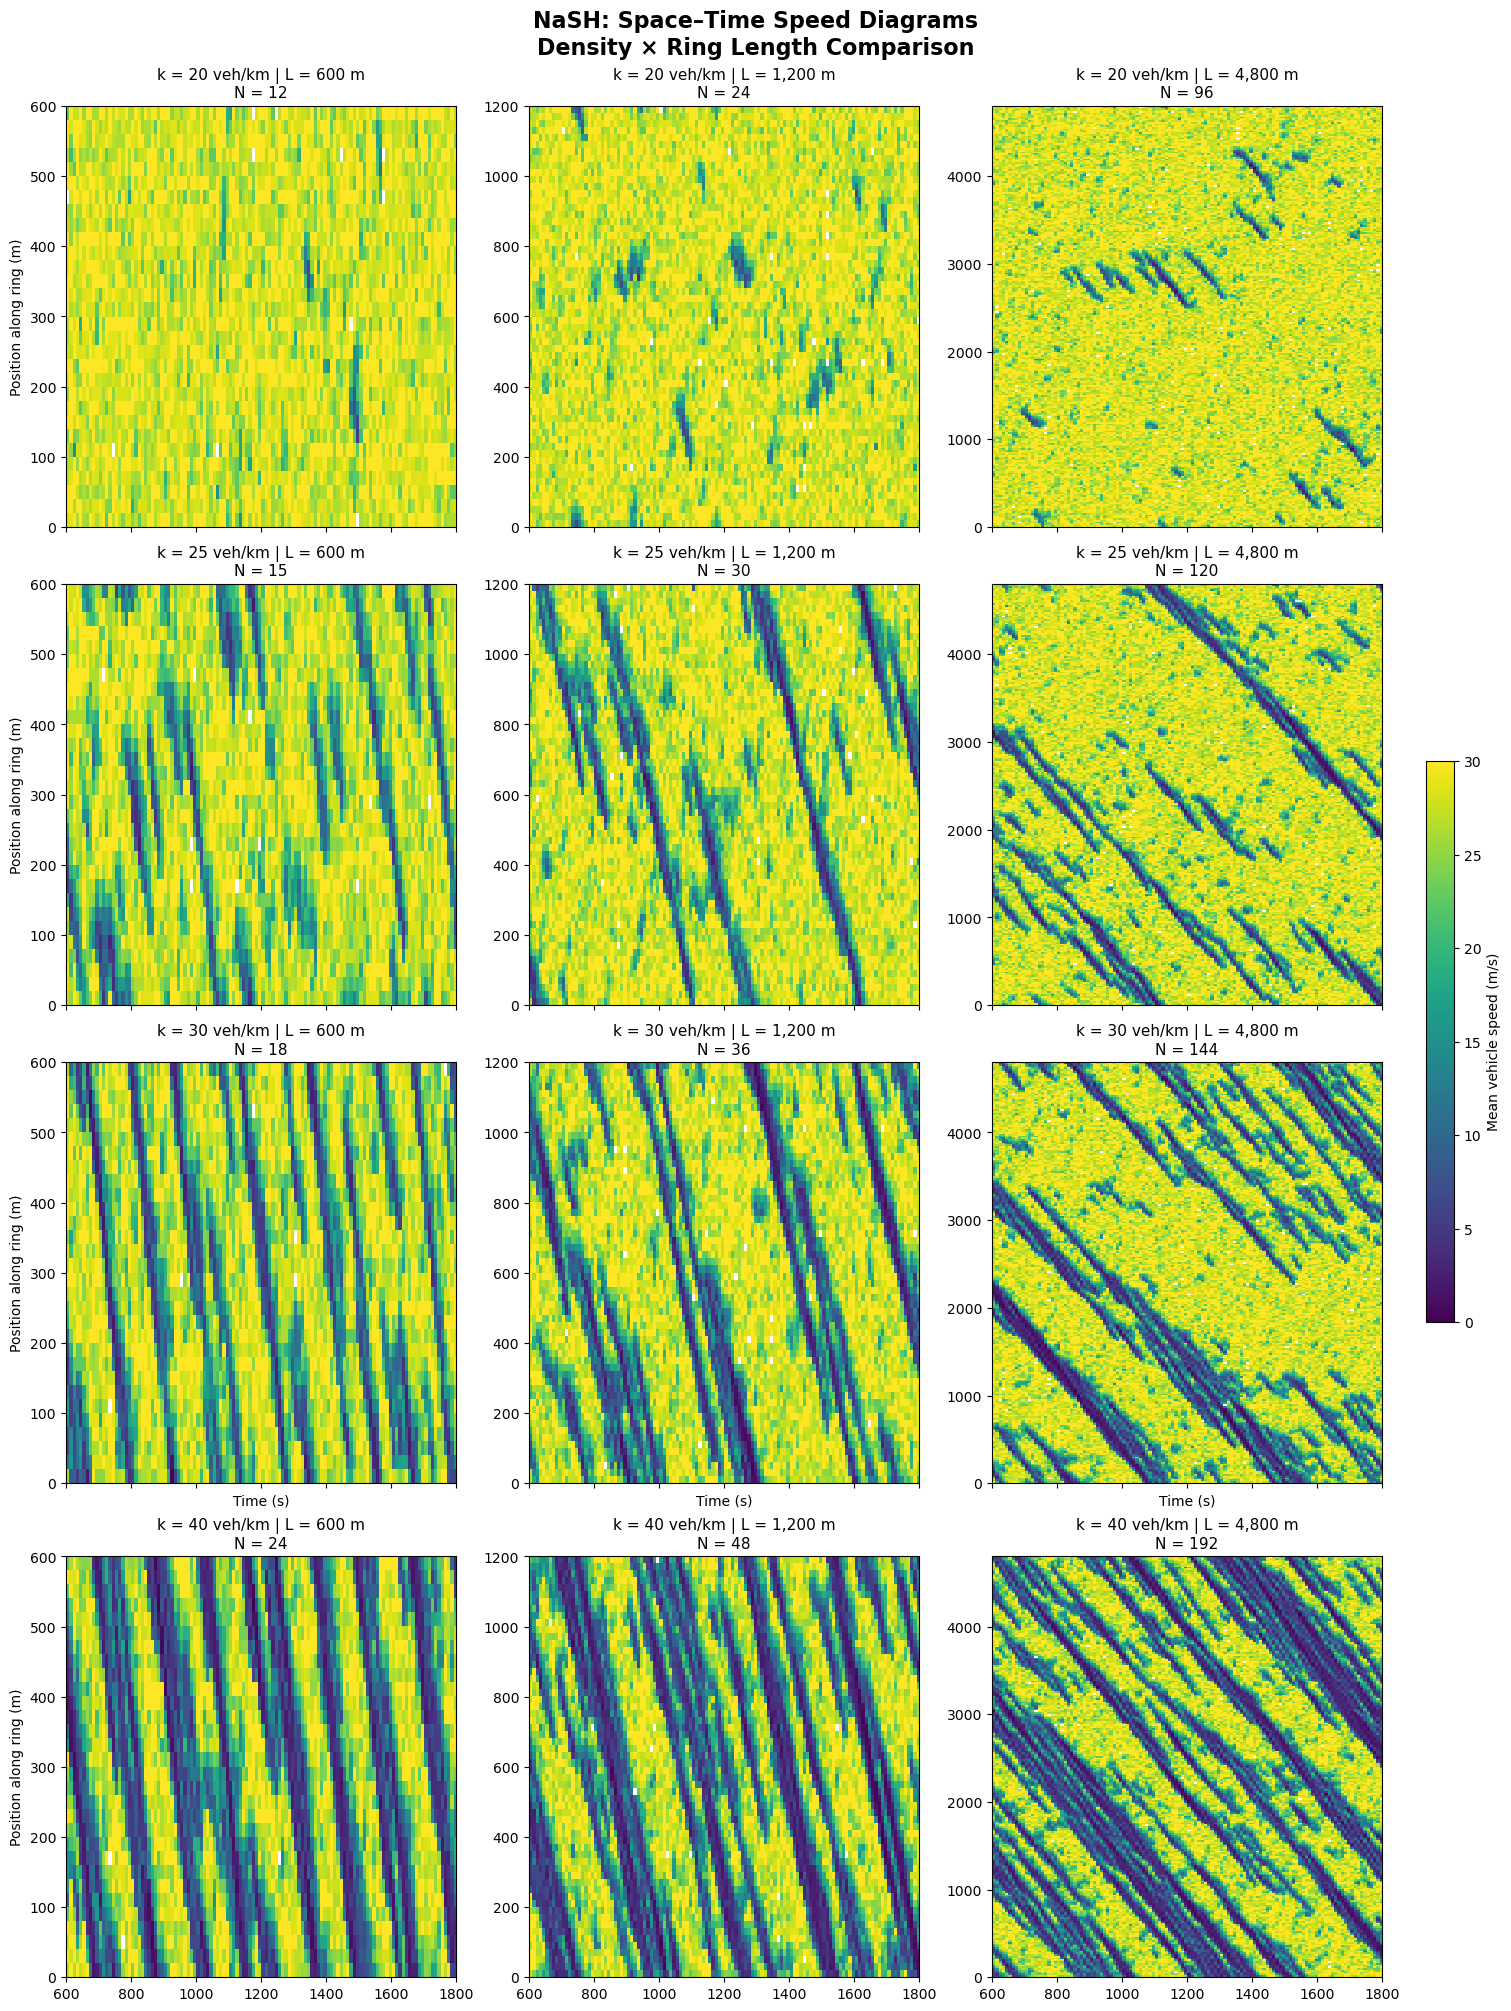

In [68]:
n_rows = len(densities)
n_cols = len(lengths)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 20), sharex=True, constrained_layout=True)

cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("white")

for row, density in enumerate(densities):

    for col, length in enumerate(lengths):
        ax = axes[row, col]
        n_vehicles = int(density * length / 1000)
        df = load_fcd_for_heatmap(length, n_vehicles, seed)

        matrix = make_speed_matrix(
            df,
            length,
            spatial_bin=spatial_bin,
            temporal_bin=temporal_bin
        )

        im = ax.imshow(
            np.ma.masked_invalid(matrix.T),
            origin="lower",
            aspect="auto",
            extent=[time_start, time_end,0,length],
            cmap=cmap, vmin=0, vmax=30,
            interpolation="nearest"
        )

        ax.set_title(
            f"k = {density} veh/km | L = {length:,} m\n"
            f"N = {n_vehicles}",
            fontsize=11
        )

        if col == 0:
            ax.set_ylabel("Position along ring (m)")

        if row == 2:
            ax.set_xlabel("Time (s)")

fig.colorbar(im, ax=axes, label="Mean vehicle speed (m/s)",shrink=0.3, pad=0.02)
fig.suptitle("NaSH: Space–Time Speed Diagrams\n" "Density × Ring Length Comparison", fontsize=16, fontweight="bold")
plt.show()

#### Experiment 2: Varying the braking probability
1. Does modifying the breaking probability affect the stop-go-waves? While keeping it at the critical density? 

In [53]:
ROOT = Path.cwd().resolve().parent

files = {
    0.00: "NaSch_sigma_L1200_N30_p0p00.csv",
    0.05: "NaSch_sigma_L1200_N30_p0p05.csv",
    0.10: "NaSch_sigma_L1200_N30_p0p10.csv",
    0.15: "NaSch_sigma_L1200_N30_p0p15.csv",
    0.20: "NaSch_sigma_L1200_N30_p0p20.csv",
    0.25: "NaSch_sigma_L1200_N30_p0p25.csv",
    0.30: "NaSch_sigma_L1200_N30_p0p30.csv",
}

frames = []

for length, filename in files.items():
    path = ROOT / "results" / "ring" / filename

    df = pd.read_csv(path)
    df["sigma"] = length
    frames.append(df)

df_sigma = pd.concat(frames, ignore_index=True)

In [54]:
df_sigma = df_sigma[df_sigma["valid"] == True].copy()

metrics = ["mean_speed_mps", "flow_veh_h", "congested_fraction", "congested_fraction_var"]

summary_sigma = (
    df_sigma
    .groupby("sigma")
    .agg(
        **{
            f"{metric}_mean": (metric, "mean")
            for metric in metrics
        },
        **{
            f"{metric}_std": (metric, "std")
            for metric in metrics
        },
        n_seeds=("seed", "nunique")
    )
    .reset_index()
    .sort_values("sigma")
)

In [55]:
df_sigma.head(5)

,run_id,scenario,model,variant,seed,density_veh_km,mean_speed_mps,flow_veh_h,congested_fraction,congested_fraction_var,valid,ring_vehicles,sigma
0,ring_nasch_sigma_0p00_L1200_n30_s501,ring,NaSch,sigma_0p00,501,25.0,30.0000,2700.000,0.000000,0.000000,True,30,0.00
1,ring_nasch_sigma_0p00_L1200_n30_s502,ring,NaSch,sigma_0p00,502,25.0,30.0000,2700.000,0.000000,0.000000,True,30,0.00
2,ring_nasch_sigma_0p00_L1200_n30_s503,ring,NaSch,sigma_0p00,503,25.0,30.0000,2700.000,0.000000,0.000000,True,30,0.00
3,ring_nasch_sigma_0p05_L1200_n30_s501,ring,NaSch,sigma_0p05,501,25.0,28.2650,2543.850,0.006639,0.000394,True,30,0.05
4,ring_nasch_sigma_0p05_L1200_n30_s502,ring,NaSch,sigma_0p05,502,25.0,28.2625,2543.625,0.008389,0.000550,True,30,0.05


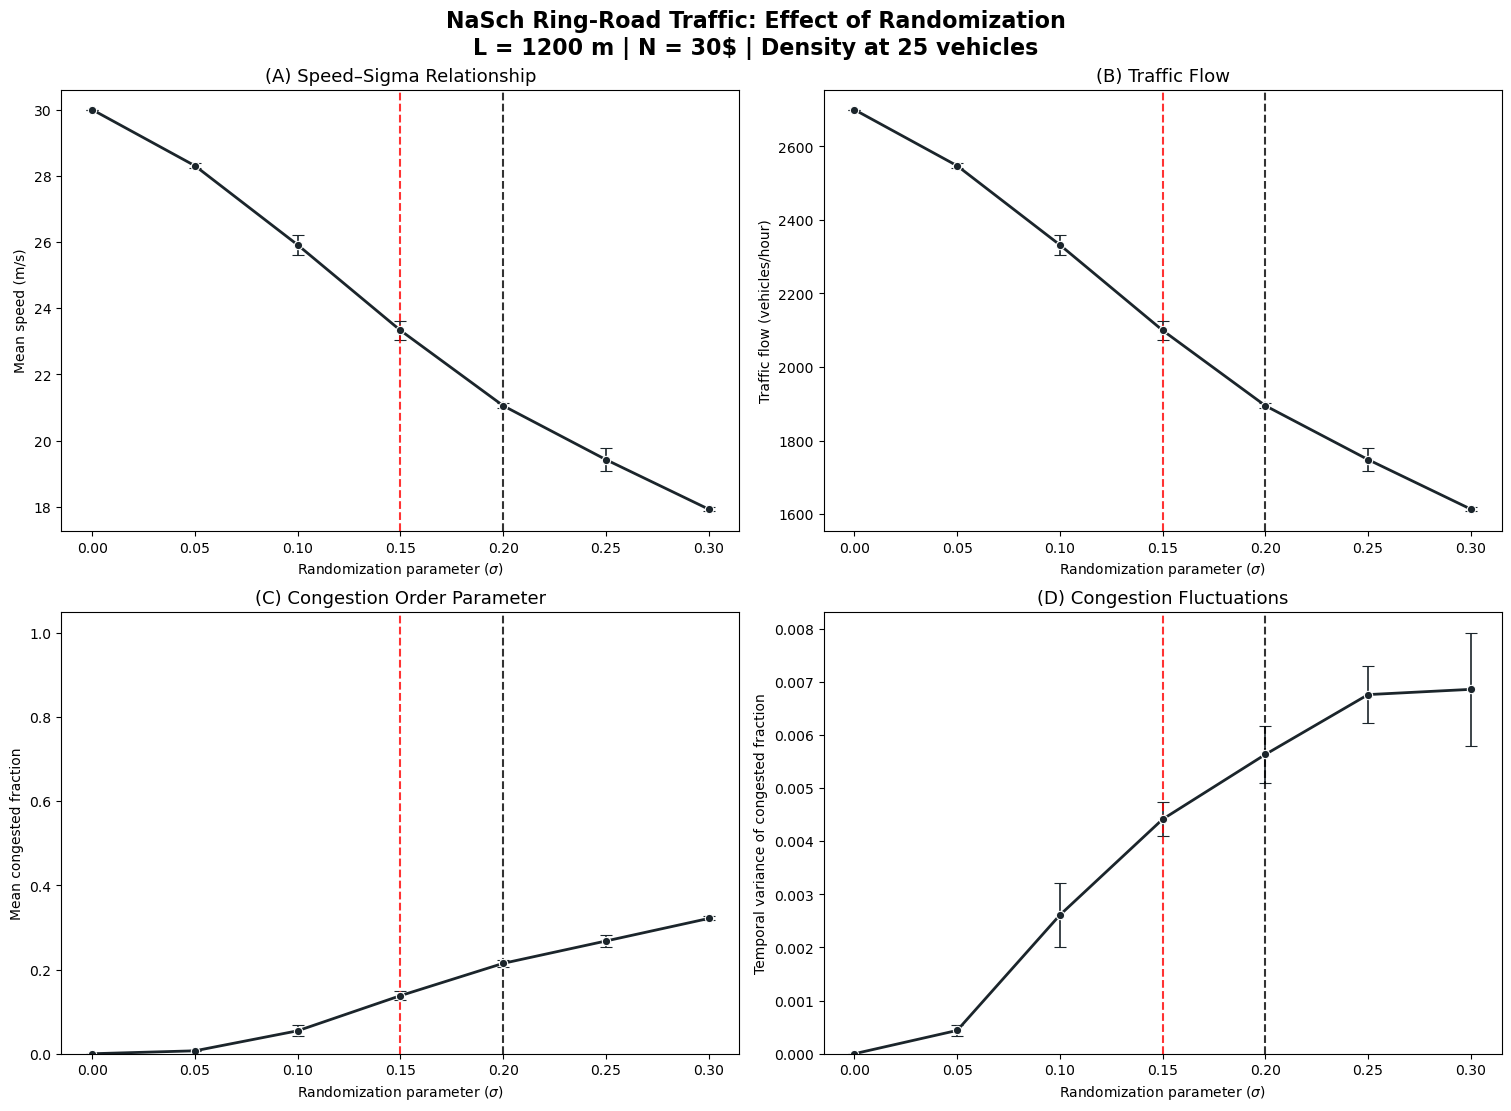

In [ ]:
# Now to plot the different sigmas 
fig, axes = plt.subplots(2, 2, figsize=(15, 11), constrained_layout=True)

plot_config = [
    {
        "metric": "mean_speed_mps",
        "title": "(A) Speed–Sigma Relationship",
        "ylabel": "Mean speed (m/s)"
    },
    {
        "metric": "flow_veh_h",
        "title": "(B) Traffic Flow",
        "ylabel": "Traffic flow (vehicles/hour)"
    },
    {
        "metric": "congested_fraction",
        "title": "(C) Congestion Order Parameter",
        "ylabel": "Mean congested fraction"
    },
    {
        "metric": "congested_fraction_var",
        "title": "(D) Congestion Fluctuations",
        "ylabel": "Temporal variance of congested fraction"
    }
]

# Publication-style color
line_color = "#1B252B"

for ax, config in zip(axes.flat, plot_config):

    metric = config["metric"]

    ax.errorbar(summary_sigma["sigma"], summary_sigma[f"{metric}_mean"],
        yerr=summary_sigma[f"{metric}_std"].fillna(0), marker="o", linestyle="-",
        linewidth=2, markersize=6, capsize=4,
        capthick=1.2, elinewidth=1.2, color=line_color, markeredgecolor="white", markeredgewidth=0.8
    )

    ax.set_title(config["title"], fontsize=13)

    ax.set_xlabel(r"Randomization parameter ($\sigma$)")
    ax.set_ylabel(config["ylabel"])

    ax.set_xticks(sorted(files.keys()))
    ax.axvline(x=0.2, color="black", linestyle="--", linewidth=1.5, alpha=0.8)
    ax.axvline(x=0.15, color="red", linestyle="--", linewidth=1.5, alpha=0.8)

axes[1, 0].set_ylim(0, 1.05)
axes[1, 1].set_ylim(bottom=0)

fig.suptitle(
    "NaSch Ring-Road Traffic: Effect of Randomization\n"
    r"L = 1200 m | N = 30 | Density at 25 vehicles",
    fontsize=16,
    fontweight="bold"
)

plt.show()

In [57]:
def load_fcd_for_sigma(seed, sigma):

    sigma_str = f"{sigma:.2f}".replace(".", "p")

    run_id = f"ring_nasch_sigma_{sigma_str}_L1200_n30_s{seed}"

    fcd_path = ROOT / "runs" / run_id / "fcd.xml"

    if not fcd_path.exists():
        raise FileNotFoundError(
            f"Missing FCD file:\n{fcd_path}\n"
            "Check the sigma, seed and run directory."
        )

    records = []

    length = 1200
    edge_length = length / 4

    for t, vehicles in iter_fcd(fcd_path):

        if not (time_start <= t < time_end):
            continue

        for vehicle in vehicles:

            edge_id = vehicle["lane"].rsplit("_", 1)[0]

            if edge_id not in {"e0", "e1", "e2", "e3"}:
                raise ValueError(f"Unexpected edge ID: {edge_id}")

            edge_index = int(edge_id[1:])

            x = (edge_index * edge_length + vehicle["pos"]) % length

            records.append({
                "time": t,
                "position": x,
                "speed": vehicle["speed"]
            })

    if not records:
        raise ValueError(f"No trajectory observations in {fcd_path}")

    return pd.DataFrame(records)

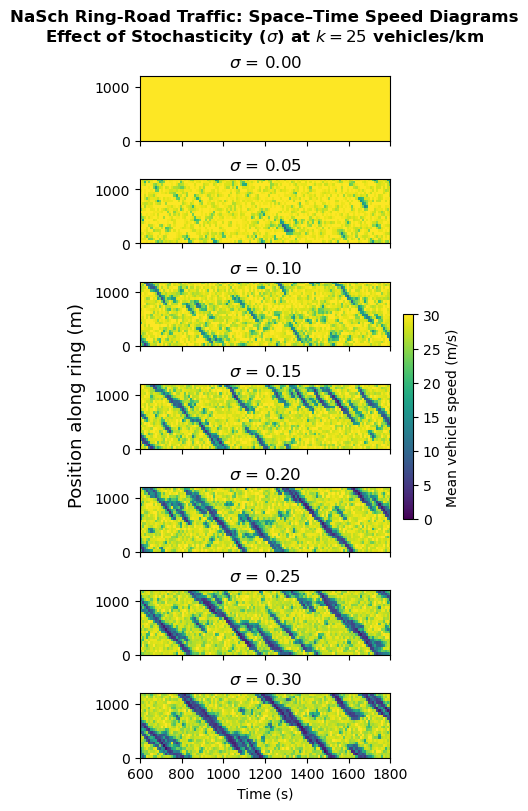

In [69]:
sigmas = [0.00, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30]

length = 1200
seed = 501

time_start = 600
time_end = 1800

spatial_bin = 50
temporal_bin = 10

n_rows = len(sigmas)

fig, axes = plt.subplots(n_rows, 1, figsize=(4, 8),sharex=True, constrained_layout=True)

cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("white")

for row, sigma in enumerate(sigmas):

    ax = axes[row]

    df = load_fcd_for_sigma(seed, sigma)

    matrix = make_speed_matrix(
        df, length, spatial_bin=spatial_bin, temporal_bin=temporal_bin)

    im = ax.imshow(np.ma.masked_invalid(matrix.T), origin="lower", aspect="auto",
        extent=[time_start, time_end, 0, length],
        cmap=cmap, vmin=0, vmax=30,
        interpolation="nearest"
    )

    ax.set_title(rf"$\sigma$ = {sigma:.2f}", fontsize=12)

    if row == n_rows - 1:
        ax.set_xlabel("Time (s)")

fig.supylabel("Position along ring (m)", fontsize=13)

fig.colorbar(im,ax=axes, label="Mean vehicle speed (m/s)", shrink=0.3, pad=0.02)

fig.suptitle(
    "NaSch Ring-Road Traffic: Space–Time Speed Diagrams\n"
    r"Effect of Stochasticity ($\sigma$) at $k = 25$ vehicles/km",
    fontsize=12,
    fontweight="bold"
)

plt.show()

#### Experiment 3: To see if removal of vehicles from the ring road for critical point can reduce in congestion decrease
1. Does modifying the breaking probability affect the stop-go-waves? Selecting the density at 25? 
2. Does the stop-go-waves revert back to free traffic flow? 

In [59]:
ROOT = Path.cwd().resolve().parent
path = ROOT / "results" / "ring" / "NaSch_1200_removal_combined.csv"
df_removal = pd.read_csv(path)
df_removal.head(5)

,run_id,model,variant,ring_length_m,initial_vehicles,seed,sigma,time_s,density_veh_km,mean_speed_mps,flow_veh_h,congested_fraction
0,ring_nasch_rem_t900_n3_t1200_n3_L1200_n12_s501,NaSch,rem_t900_n3_t1200_n3,1200,12,501,0.2,0.0,10.0,0.000,0.0,1.0000
1,ring_nasch_rem_t900_n3_t1200_n3_L1200_n12_s501,NaSch,rem_t900_n3_t1200_n3,1200,12,501,0.2,10.0,10.0,24.375,877.5,0.0833
2,ring_nasch_rem_t900_n3_t1200_n3_L1200_n12_s501,NaSch,rem_t900_n3_t1200_n3,1200,12,501,0.2,20.0,10.0,28.750,1035.0,0.0000
3,ring_nasch_rem_t900_n3_t1200_n3_L1200_n12_s501,NaSch,rem_t900_n3_t1200_n3,1200,12,501,0.2,30.0,10.0,27.500,990.0,0.0000
4,ring_nasch_rem_t900_n3_t1200_n3_L1200_n12_s501,NaSch,rem_t900_n3_t1200_n3,1200,12,501,0.2,40.0,10.0,28.125,1012.5,0.0000


In [60]:
from matplotlib.colors import Normalize

phase_conditions = [df_removal["time_s"].between(600, 890), df_removal["time_s"].between(970, 1190), df_removal["time_s"].between(1270, 1790),]
phase_names = ["Before removal", "After first removal", "After second removal",]
df_removal["phase"] = np.select(phase_conditions, phase_names,default=None,)
df_steady = df_removal.loc[df_removal["phase"].notna()].copy()
df_steady["phase"] = pd.Categorical(df_steady["phase"], categories=phase_names, ordered=True,)

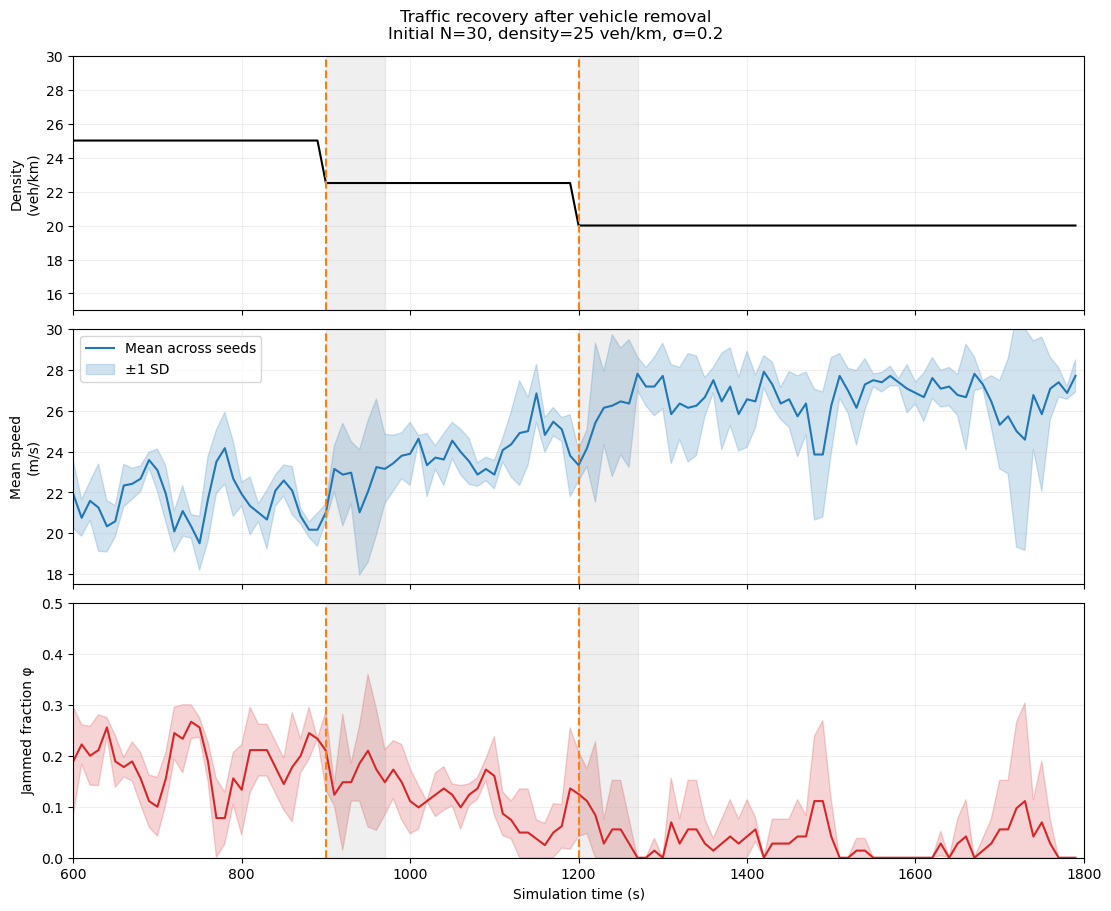

In [61]:
selected_n = 30

df_focus = df_removal.loc[df_removal["initial_vehicles"].eq(selected_n)].copy()

time_summary = (
    df_focus
    .groupby("time_s", as_index=False)
    .agg(
        density_mean=("density_veh_km", "mean"),
        speed_mean=("mean_speed_mps", "mean"),
        speed_std=("mean_speed_mps", "std"),
        phi_mean=("congested_fraction", "mean"),
        phi_std=("congested_fraction", "std"),
    )
)

fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True, constrained_layout=True,)

# Density
axes[0].plot(time_summary["time_s"], time_summary["density_mean"], color="black",)
axes[0].set_ylabel("Density\n(veh/km)")

# Mean speed
axes[1].plot(
    time_summary["time_s"],
    time_summary["speed_mean"],
    color="tab:blue",
    label="Mean across seeds",
)
axes[1].fill_between(
    time_summary["time_s"],
    time_summary["speed_mean"] - time_summary["speed_std"],
    time_summary["speed_mean"] + time_summary["speed_std"],
    color="tab:blue",
    alpha=0.2,
    label="±1 SD",
)
axes[1].set_ylabel("Mean speed\n(m/s)")
axes[1].legend()

# Jammed fraction
axes[2].plot(time_summary["time_s"], time_summary["phi_mean"], color="tab:red",)
axes[2].fill_between(time_summary["time_s"], np.maximum(0,time_summary["phi_mean"] - time_summary["phi_std"],),
    np.minimum(1, time_summary["phi_mean"] + time_summary["phi_std"],), color="tab:red", alpha=0.2,)
axes[2].set_ylabel("Jammed fraction φ")
axes[2].set_xlabel("Simulation time (s)")
axes[2].set_ylim(0, 1)

for ax in axes:
    ax.set_xlim(600, 1800)
    ax.axvline(900, color="tab:orange", linestyle="--")
    ax.axvline(1200, color="tab:orange", linestyle="--")
    ax.axvspan(900, 970, color="grey", alpha=0.12)
    ax.axvspan(1200, 1270, color="grey", alpha=0.12)
    ax.grid(alpha=0.2)

# Set individual Y-axis ranges
axes[0].set_ylim(15, 30)     # Density (veh/km)
axes[1].set_ylim(17.5, 30)     # Mean speed (m/s)
axes[2].set_ylim(0, 0.5)    # Jammed fraction
fig.suptitle(
    "Traffic recovery after vehicle removal\n"
    "Initial N=30, density=25 veh/km, σ=0.2"
)

plt.show()

In [62]:
# Just for the specific n chosen
fcd_path = (
    ROOT
    / "runs"
    / "ring_nasch_rem_t900_n3_t1200_n3_L1200_n30_s501"
    / "fcd.xml"
)

In [63]:
import xml.etree.ElementTree as ET

RING_LENGTH = 1200
EDGE_LENGTH = RING_LENGTH / 4

edge_index = {"e0": 0, "e1": 1, "e2": 2, "e3": 3,}

space_time_rows = []

for _, timestep in ET.iterparse(fcd_path, events=("end",)):
    if timestep.tag != "timestep":
        continue

    time_s = float(timestep.get("time"))

    if 600 <= time_s <= 1500:
        for vehicle in timestep:
            lane_id = vehicle.get("lane")
            edge_id = lane_id.split("_")[0]

            # Ignore any unexpected internal junction lanes.
            if edge_id not in edge_index:
                continue

            position = (
                edge_index[edge_id] * EDGE_LENGTH
                + float(vehicle.get("pos"))
            )

            space_time_rows.append({
                "time_s": time_s,
                "vehicle_id": vehicle.get("id"),
                "position_m": position,
                "speed_mps": float(vehicle.get("speed")),
            })

    timestep.clear()

df_space_time = pd.DataFrame(space_time_rows)

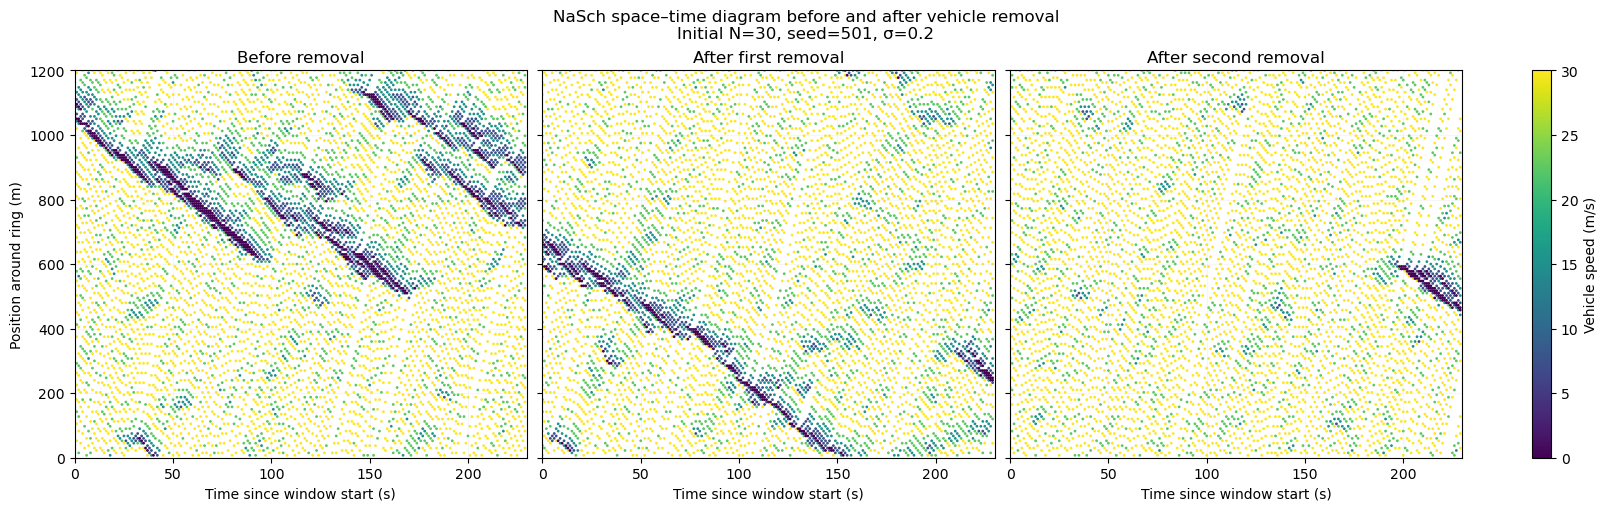

In [64]:
windows = [
    ("Before removal", 670, 900),
    ("After first removal", 970, 1200),
    ("After second removal", 1270, 1500),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True, constrained_layout=True,)

norm = Normalize(vmin=0, vmax=30)

for ax, (title, start, end) in zip(axes, windows):
    data = df_space_time.loc[
        df_space_time["time_s"].between(
            start,
            end,
            inclusive="left",
        )
    ].copy()

    scatter = ax.scatter(data["time_s"] - start, data["position_m"], c=data["speed_mps"], cmap="viridis", norm=norm, s=1, rasterized=True,)

    ax.set_title(title)
    ax.set_xlabel("Time since window start (s)")
    ax.set_xlim(0, end - start)
    ax.set_ylim(0, RING_LENGTH)
    ax.grid(alpha=0.1)

axes[0].set_ylabel("Position around ring (m)")

fig.colorbar(scatter, ax=axes, label="Vehicle speed (m/s)",)
fig.suptitle("NaSch space–time diagram before and after vehicle removal\n" "Initial N=30, seed=501, σ=0.2")

plt.show()

From stimulation peaks near 20 veh/km and the backward moving low-speed clusters is persistent at 25 - 30 veh and higher densities gives wider congestion bands

Removal experiment:
Density falls from 25 to 22.5 and then 20 veh/km.
Mean speed increases.
Mean jammed fraction decreases.
The large congestion bands become fewer and shorter.